# 03 · Validación cruzada repetida por paciente — DERM12345 acral

**Por qué este notebook.** Las v1 y v2 se evaluaban con el test del paper, pero los 136
melanomas acrales son solo **24 pacientes** (16 en train, 8 en test; uno aporta 22 imágenes).
Con 8 pacientes en test, el resultado depende de quién cae ahí: en la v2 el umbral daba
sensibilidad 0,90 en validación cruzada y 0,76 en test **dentro del mismo subgrupo**.

**Qué hace:**
1. **Validación cruzada 5 × 3 sobre las 896 imágenes**, agrupada por paciente: los
   24 pacientes con melanoma pasan por test, en 3 repartos distintos. Resultado: media ± desviación.
2. **Compara dos preprocesamientos con los mismos repartos** (cambia una sola cosa):
   `resize` (como la v1) y `lesion_crop` (recorte centrado en la lesión, como la v2).
3. **Umbral sin mirar el fold evaluado:** para cada fold, el umbral se elige con las
   predicciones *out-of-fold* de los otros 4 (sensibilidad objetivo 0,95).
4. **Métricas por paciente** (¿cuántos de los 24 pacientes se detectan?), **por cámara**
   (resolución original) y por **split del paper**.

### Dónde ejecutarlo
- **Kaggle (recomendado):** *Create → New Notebook → File → Import Notebook →* pega la URL de
  GitHub de este fichero. En el panel derecho: *Accelerator → GPU T4 x2* (o P100) e
  *Internet → On* (requiere verificar el teléfono una vez). Luego **Save Version → Save & Run All**:
  se ejecuta en segundo plano y puedes cerrar el navegador. Los resultados quedan en *Output*.
- **Colab:** <https://colab.research.google.com/github/Mangelits/AcralisisPodoScan/blob/main/notebooks/03_repeated_cv_derm12345.ipynb>
  con GPU T4. Si la sesión se corta, vuelve a ejecutarlo: **retoma los folds ya hechos**.

Duración estimada: 15 entrenamientos por preprocesamiento, 30 en total → **~1,5–2 h** en una T4
(la mitad si dejas un solo preprocesamiento en `PREPROCS`).

In [1]:
# ---- Configuración -------------------------------------------------------
REPO_URL = "https://github.com/Mangelits/AcralisisPodoScan.git"
BRANCH = "main"
USE_DRIVE = True               # solo Colab: guarda imágenes y resultados en Google Drive
RUN_NAME = "v3_repeated_cv"    # cámbialo para no reanudar una ejecución anterior

PREPROCS = ["resize", "lesion_crop"]   # quita uno para ir el doble de rápido
N_FOLDS = 5
N_REPEATS = 3
SEED = 42
IMG_SIZE = 224
CACHE_SIZE = 384
CROP_MARGIN = 1.5
EPOCHS = 20                    # fijo, sin early stopping: se usa la última época
BATCH_SIZE = 32
LR = 3e-4
WEIGHT_DECAY = 1e-4
TARGET_SENSITIVITY = 0.95

In [2]:
import os
import subprocess
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
IN_KAGGLE = Path("/kaggle/working").exists()

if IN_COLAB or IN_KAGGLE:
    repo = Path("/content/AcralisisPodoScan") if IN_COLAB else Path("/tmp/AcralisisPodoScan")
    try:
        if not repo.exists():
            subprocess.run(["git", "clone", "-q", "-b", BRANCH, REPO_URL, str(repo)], check=True)
        subprocess.run(["git", "-C", str(repo), "pull", "-q"], check=True)
    except subprocess.CalledProcessError:
        raise RuntimeError(
            "No se pudo clonar el repo: el notebook no tiene Internet. En Kaggle: panel derecho → "
            "Session options → Internet → On (requiere verificar el teléfono en Settings)."
        ) from None
    os.chdir(repo)
if IN_COLAB and USE_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")

ROOT = Path.cwd() if (Path.cwd() / "scripts").exists() else Path.cwd().parent
if IN_COLAB and USE_DRIVE:
    STORE = Path("/content/drive/MyDrive/acralis")
    RAW_DIR, OUT_DIR = STORE / "data" / "raw" / "derm12345", STORE / "models"
elif IN_KAGGLE:
    RAW_DIR, OUT_DIR = ROOT / "data" / "raw" / "derm12345", Path("/kaggle/working/outputs")
else:  # en local, todo dentro de data/ (ignorado por git)
    RAW_DIR, OUT_DIR = ROOT / "data" / "raw" / "derm12345", ROOT / "data" / "processed" / "models"
CACHE_DIRS = {p: ROOT / "data" / "processed" / f"derm12345_{p}_{CACHE_SIZE}" for p in PREPROCS}
for d in (RAW_DIR, OUT_DIR, *CACHE_DIRS.values()):
    d.mkdir(parents=True, exist_ok=True)

sys.path.insert(0, str(ROOT / "ms2-procesamiento"))
from app.preprocessing import lesion_crop   # mismo código que usará /analyze

assert set(PREPROCS) <= {"resize", "lesion_crop"}, PREPROCS
NUM_WORKERS = min(4, os.cpu_count() or 2)
print("Entorno:", "Kaggle" if IN_KAGGLE else "Colab" if IN_COLAB else "local")
print("RAW_DIR:", RAW_DIR, "\nOUT_DIR:", OUT_DIR)

Entorno: Kaggle
RAW_DIR: /tmp/AcralisisPodoScan/data/raw/derm12345 
OUT_DIR: /kaggle/working/outputs


## 1 · Datos

In [3]:
r = subprocess.run([sys.executable, "scripts/datasets/download_derm12345.py", "--out", str(RAW_DIR)],
                   capture_output=True, text=True)
print(r.stdout[-1500:], r.stderr[-3000:])

acral_csv = RAW_DIR / "acral.csv"
n_rows = sum(1 for _ in open(acral_csv)) - 1 if acral_csv.exists() else 0
assert n_rows == 896, (
    f"acral.csv tiene {n_rows} de 896 imágenes. Revisa los errores (✗) de arriba y vuelve a "
    "ejecutar esta celda: la descarga es reanudable."
)
print("✓ 896 imágenes acrales listas")

Descargando derm12345.csv…
Descargando derm12345_supplemental.csv…
896 imágenes acrales a obtener en /tmp/AcralisisPodoScan/data/raw/derm12345/images
  25/896
  50/896
  75/896
  100/896
  125/896
  150/896
  175/896
  200/896
  225/896
  250/896
  275/896
  300/896
  325/896
  350/896
  375/896
  400/896
  425/896
  450/896
  475/896
  500/896
  525/896
  550/896
  575/896
  600/896
  625/896
  650/896
  675/896
  700/896
  725/896
  750/896
  775/896
  800/896
  825/896
  850/896
  875/896
  896/896
Hecho: 896 OK, 0 fallidas → /tmp/AcralisisPodoScan/data/raw/derm12345/acral.csv
 
✓ 896 imágenes acrales listas


In [4]:
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
from PIL import Image, ImageOps

def to_cache(img: Image.Image, preproc: str) -> Image.Image:
    if preproc == "resize":   # lado corto a CACHE_SIZE, conserva la forma (como la v1)
        scale = CACHE_SIZE / min(img.size)
        if scale >= 1:
            return img
        return img.resize((round(img.width * scale), round(img.height * scale)), Image.LANCZOS)
    crop, _ = lesion_crop(np.asarray(img), margin=CROP_MARGIN)   # cuadrado centrado (como la v2)
    return Image.fromarray(crop).resize((CACHE_SIZE, CACHE_SIZE), Image.LANCZOS)

def process(src: Path) -> dict:
    img = ImageOps.exif_transpose(Image.open(src)).convert("RGB")
    for p in PREPROCS:
        dst = CACHE_DIRS[p] / src.name
        if not dst.exists():
            to_cache(img, p).save(dst, quality=95)
    return {"isic_id": src.stem, "orig_w": img.width, "orig_h": img.height}

sources = sorted((RAW_DIR / "images").glob("*.jpg"))
with ThreadPoolExecutor(NUM_WORKERS * 2) as pool:
    sizes = pd.DataFrame(list(pool.map(process, sources)))

df = pd.read_csv(RAW_DIR / "acral.csv").merge(sizes, on="isic_id")
df["target"] = (df["malignancy"] == "malignant").astype(int)
for p in PREPROCS:
    df[f"path_{p}"] = [str(CACHE_DIRS[p] / Path(f).name) for f in df["file"]]

# Cámara ≈ resolución original. Las poco frecuentes (<10 imágenes) son recortes a mano.
size = df.orig_w.astype(str) + "×" + df.orig_h.astype(str)
frequent = size.map(size.value_counts()) >= 10
df["camera"] = np.where(frequent, size, "irregular")
df["subgroup"] = np.where(frequent, "estándar", "recortada")

mel = df[df.target == 1]
print(f"{len(df)} imágenes · {df.patient_id.nunique()} pacientes · "
      f"{len(mel)} melanomas de {mel.patient_id.nunique()} pacientes")
print("Imágenes de melanoma por paciente:", sorted(mel.patient_id.value_counts().tolist(), reverse=True))
pd.crosstab(df.camera, df.target.map({0: "benigno", 1: "melanoma"}), margins=True)

896 imágenes · 351 pacientes · 136 melanomas de 24 pacientes
Imágenes de melanoma por paciente: [22, 15, 8, 8, 7, 7, 6, 5, 5, 5, 5, 5, 5, 5, 5, 4, 4, 3, 3, 3, 2, 2, 1, 1]


target,benigno,melanoma,All
camera,,,
1920×1080,75,0,75
2048×1536,3,8,11
3264×2448,130,9,139
4032×3024,101,9,110
768×576,400,40,440
irregular,51,70,121
All,760,136,896


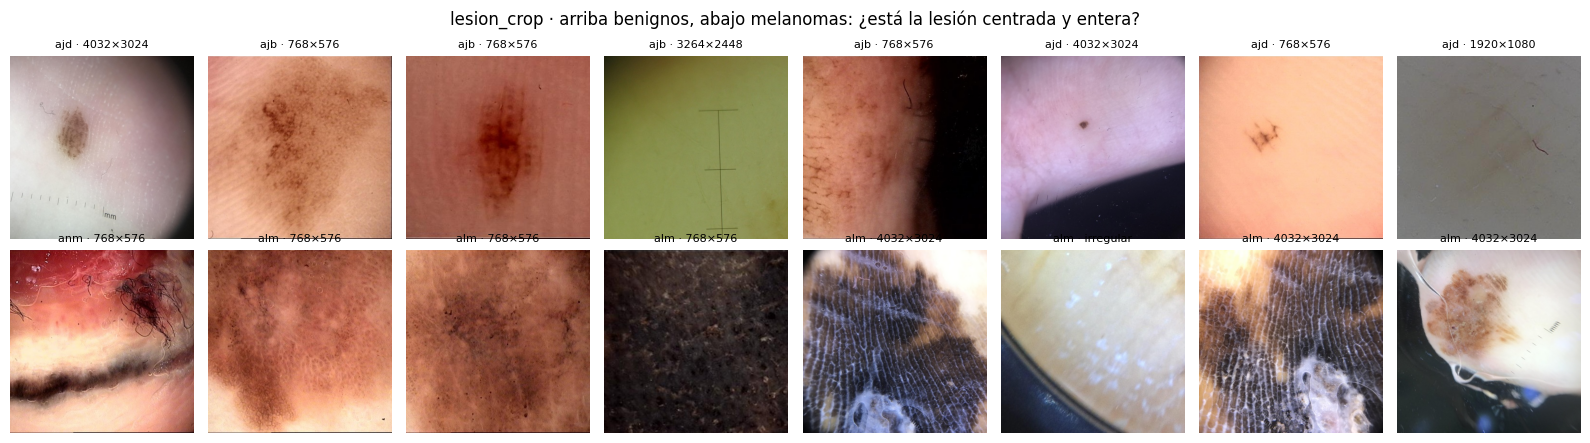

In [5]:
import matplotlib.pyplot as plt

if "lesion_crop" in PREPROCS:   # inspección visual del recorte
    fig, axes = plt.subplots(2, 8, figsize=(16, 4.5))
    for row, t in zip(axes, (0, 1)):
        for ax, (_, r) in zip(row, df[df.target == t].sample(8, random_state=SEED).iterrows()):
            ax.imshow(Image.open(r.path_lesion_crop)); ax.set_title(f"{r.label} · {r.camera}", fontsize=8)
        for ax in row:
            ax.axis("off")
    fig.suptitle("lesion_crop · arriba benignos, abajo melanomas: ¿está la lesión centrada y entera?")
    plt.tight_layout(); plt.show()

## 2 · Entrenamiento

In [6]:
import random
import time

import torch
from sklearn.metrics import confusion_matrix, roc_auc_score, roc_curve
from sklearn.model_selection import StratifiedGroupKFold
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms as T
from torchvision.models import EfficientNet_B0_Weights, efficientnet_b0

def seed_everything(seed: int) -> None:
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
AMP = DEVICE.type == "cuda"
print("Dispositivo:", DEVICE, torch.cuda.get_device_name(0) if AMP else "", "· workers:", NUM_WORKERS)
if not AMP:
    print("⚠️ Sin GPU: actívala (Kaggle: Accelerator · Colab: Cambiar tipo de entorno).")

MEAN, STD = (0.485, 0.456, 0.406), (0.229, 0.224, 0.225)
AUGMENT = [T.RandomHorizontalFlip(), T.RandomVerticalFlip(), T.RandomRotation(180),
           T.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.1, hue=0.02),
           T.ToTensor(), T.Normalize(MEAN, STD)]
TRAIN_TF = {
    "resize": T.Compose([T.RandomResizedCrop(IMG_SIZE, scale=(0.5, 1.0)), *AUGMENT]),
    "lesion_crop": T.Compose([T.RandomResizedCrop(IMG_SIZE, scale=(0.7, 1.0), ratio=(0.9, 1.1)), *AUGMENT]),
}
EVAL_TF = {
    "resize": T.Compose([T.Resize(IMG_SIZE), T.CenterCrop(IMG_SIZE), T.ToTensor(), T.Normalize(MEAN, STD)]),
    "lesion_crop": T.Compose([T.Resize((IMG_SIZE, IMG_SIZE)), T.ToTensor(), T.Normalize(MEAN, STD)]),
}

class LesionDataset(Dataset):
    def __init__(self, frame: pd.DataFrame, preproc: str, train: bool):
        self.paths, self.targets = frame[f"path_{preproc}"].tolist(), frame["target"].tolist()
        self.tf = (TRAIN_TF if train else EVAL_TF)[preproc]
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, i):
        return self.tf(Image.open(self.paths[i]).convert("RGB")), torch.tensor(self.targets[i], dtype=torch.float32)

def make_loader(frame, preproc, train):
    return DataLoader(LesionDataset(frame, preproc, train), batch_size=BATCH_SIZE, shuffle=train,
                      drop_last=train, num_workers=NUM_WORKERS, pin_memory=AMP, persistent_workers=train)

@torch.no_grad()
def predict(model, frame, preproc) -> np.ndarray:
    model.eval(); probs = []
    for x, _ in make_loader(frame, preproc, train=False):
        with torch.autocast(DEVICE.type, enabled=AMP):
            probs.append(torch.sigmoid(model(x.to(DEVICE, non_blocking=True)).squeeze(1).float()).cpu().numpy())
    return np.concatenate(probs)

def train_model(frame: pd.DataFrame, preproc: str, seed: int):
    seed_everything(seed)
    model = efficientnet_b0(weights=EfficientNet_B0_Weights.IMAGENET1K_V1)
    model.classifier[1] = torch.nn.Linear(model.classifier[1].in_features, 1)
    model = model.to(DEVICE)
    dl = make_loader(frame, preproc, train=True)
    pos_weight = torch.tensor((frame.target == 0).sum() / (frame.target == 1).sum(), device=DEVICE)
    criterion = torch.nn.BCEWithLogitsLoss(pos_weight=pos_weight)
    optimizer = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=LR, epochs=EPOCHS,
                                                    steps_per_epoch=len(dl), pct_start=0.15)
    scaler = torch.amp.GradScaler(enabled=AMP)
    losses = []
    for _ in range(EPOCHS):
        model.train(); running = 0.0
        for x, y in dl:
            x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
            optimizer.zero_grad(set_to_none=True)
            with torch.autocast(DEVICE.type, enabled=AMP):
                loss = criterion(model(x).squeeze(1), y)
            scaler.scale(loss).backward(); scaler.step(optimizer); scaler.update(); scheduler.step()
            running += loss.item()
        losses.append(running / len(dl))
    return model, losses

Dispositivo: cuda Tesla T4 · workers: 4


### Repartos (los mismos para ambos preprocesamientos) y bucle de validación cruzada

Las predicciones se guardan tras **cada** fold en `OUT_DIR/{RUN_NAME}_oof.csv`: si la sesión
se corta, al relanzar se saltan los folds ya hechos.

In [7]:
# Repartos: cada repetición usa otra semilla; cada paciente cae entero en un fold.
for r in range(N_REPEATS):
    sgkf = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED + r)
    df[f"fold_r{r}"] = -1
    for k, (_, va) in enumerate(sgkf.split(df, df.target, groups=df.patient_id)):
        df.loc[va, f"fold_r{r}"] = k
    assert (df.groupby("patient_id")[f"fold_r{r}"].nunique() == 1).all()

print("Pacientes con melanoma por fold:")
print(pd.DataFrame({f"rep {r}": df[df.target == 1].groupby(f"fold_r{r}").patient_id.nunique()
                    for r in range(N_REPEATS)}))

oof_path = OUT_DIR / f"{RUN_NAME}_oof.csv"
pred_cols = [f"p_{p}_r{r}" for p in PREPROCS for r in range(N_REPEATS)]
if oof_path.exists():
    saved = pd.read_csv(oof_path).set_index("isic_id")
    for c in pred_cols:
        df[c] = df.isic_id.map(saved[c]) if c in saved else np.nan
    print(f"Reanudando desde {oof_path}")
else:
    for c in pred_cols:
        df[c] = np.nan

Pacientes con melanoma por fold:
   rep 0  rep 1  rep 2
0      4      7      7
1      2      4      4
2     11      5      7
3      2      4      1
4      5      4      5


In [8]:
t_start = time.time()
for p in PREPROCS:
    for r in range(N_REPEATS):
        col, fcol = f"p_{p}_r{r}", f"fold_r{r}"
        for k in range(N_FOLDS):
            va = df[fcol] == k
            if df.loc[va, col].notna().all():
                continue   # ya hecho en una ejecución anterior
            t0 = time.time()
            model, losses = train_model(df[~va], p, seed=SEED + 100 * r + k)
            df.loc[va, col] = predict(model, df[va], p)
            del model; torch.cuda.empty_cache()
            y_k = df.loc[va, "target"]
            auc_k = roc_auc_score(y_k, df.loc[va, col]) if 0 < y_k.sum() < len(y_k) else float("nan")
            print(f"[{p} · rep {r} · fold {k}] AUC {auc_k:.3f} · loss final {losses[-1]:.3f} · "
                  f"{time.time() - t0:.0f}s (total {(time.time() - t_start) / 60:.0f} min)")
            df[["isic_id"] + pred_cols].to_csv(oof_path, index=False)   # punto de control
print("✓ Validación cruzada completa")

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 167MB/s]


[resize · rep 0 · fold 0] AUC 1.000 · loss final 0.042 · 78s (total 1 min)
[resize · rep 0 · fold 1] AUC 1.000 · loss final 0.017 · 65s (total 2 min)
[resize · rep 0 · fold 2] AUC 0.985 · loss final 0.022 · 64s (total 3 min)
[resize · rep 0 · fold 3] AUC 0.801 · loss final 0.014 · 69s (total 5 min)
[resize · rep 0 · fold 4] AUC 1.000 · loss final 0.034 · 63s (total 6 min)
[resize · rep 1 · fold 0] AUC 0.989 · loss final 0.028 · 62s (total 7 min)
[resize · rep 1 · fold 1] AUC 1.000 · loss final 0.021 · 63s (total 8 min)
[resize · rep 1 · fold 2] AUC 1.000 · loss final 0.036 · 66s (total 9 min)
[resize · rep 1 · fold 3] AUC 0.996 · loss final 0.031 · 63s (total 10 min)
[resize · rep 1 · fold 4] AUC 0.945 · loss final 0.038 · 66s (total 11 min)
[resize · rep 2 · fold 0] AUC 0.994 · loss final 0.026 · 66s (total 12 min)
[resize · rep 2 · fold 1] AUC 0.936 · loss final 0.064 · 69s (total 13 min)
[resize · rep 2 · fold 2] AUC 1.000 · loss final 0.064 · 62s (total 14 min)
[resize · rep 2 · fo

## 3 · Resultados

Para cada fold, el umbral se elige con las predicciones de los **otros** folds de la misma
repetición (sensibilidad objetivo 0,95) y se aplica al fold. Así ningún fold elige su propio umbral.

In [9]:
def threshold_for_sensitivity(y, p, target):
    fpr, tpr, thr = roc_curve(y, p)
    return float(thr[np.argmax(tpr >= target)])

def apply_thresholds(p_col: str, r: int) -> np.ndarray:
    """Predicción binaria con umbral elegido fuera de cada fold."""
    fold, y, p = df[f"fold_r{r}"].values, df.target.values, df[p_col].values
    pred = np.zeros(len(df), dtype=int)
    for k in range(N_FOLDS):
        m = fold == k
        pred[m] = p[m] >= threshold_for_sensitivity(y[~m], p[~m], TARGET_SENSITIVITY)
    return pred

def rates(y, p, pred) -> dict:
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return {"auc": roc_auc_score(y, p) if 0 < y.sum() < len(y) else np.nan,
            "sensibilidad": tp / (tp + fn) if tp + fn else np.nan,
            "especificidad": tn / (tn + fp) if tn + fp else np.nan,
            "melanomas_detectados": f"{tp}/{tp + fn}", "falsas_alarmas": f"{fp}/{fp + tn}"}

for p in PREPROCS:
    for r in range(N_REPEATS):
        df[f"pred_{p}_r{r}"] = apply_thresholds(f"p_{p}_r{r}", r)

# Una fila por (preprocesamiento, repetición) y un resumen media ± desviación.
rows, fold_aucs, patient_rows = [], [], []
mel_patients = df[df.target == 1].patient_id.unique()
for p in PREPROCS:
    for r in range(N_REPEATS):
        y, prob, pred = df.target.values, df[f"p_{p}_r{r}"].values, df[f"pred_{p}_r{r}"].values
        det = df[df.target == 1].assign(d=pred[df.target.values == 1]).groupby("patient_id").d.max()
        rows.append({"preproc": p, "rep": r, **rates(y, prob, pred),
                     "pacientes_detectados": f"{int(det.sum())}/{len(mel_patients)}",
                     "frac_pacientes": det.mean()})
        for k in range(N_FOLDS):
            m = df[f"fold_r{r}"] == k
            if 0 < df.target[m].sum() < m.sum():
                fold_aucs.append({"preproc": p, "rep": r, "fold": k,
                                  "auc": roc_auc_score(df.target[m], df[f"p_{p}_r{r}"][m])})
per_rep = pd.DataFrame(rows)
fold_aucs = pd.DataFrame(fold_aucs)

summary = per_rep.groupby("preproc")[["auc", "sensibilidad", "especificidad", "frac_pacientes"]].agg(["mean", "std"])
summary[("auc_por_fold", "mean")] = fold_aucs.groupby("preproc").auc.mean()
summary[("auc_por_fold", "std")] = fold_aucs.groupby("preproc").auc.std()
print("Por repetición (5 folds juntos):")
display(per_rep.round(3))
print("Resumen (media ± desviación entre repeticiones; AUC por fold entre los 15 folds):")
display(summary.round(3))

Por repetición (5 folds juntos):


,preproc,rep,auc,sensibilidad,especificidad,melanomas_detectados,falsas_alarmas,pacientes_detectados,frac_pacientes
0,resize,0,0.981,0.890,0.962,121/136,29/760,22/24,0.917
1,resize,1,0.985,0.956,0.968,130/136,24/760,23/24,0.958
2,resize,2,0.982,0.897,0.926,122/136,56/760,23/24,0.958
3,lesion_crop,0,0.985,0.912,0.963,124/136,28/760,23/24,0.958
4,lesion_crop,1,0.979,0.963,0.941,131/136,45/760,23/24,0.958
5,lesion_crop,2,0.982,0.875,0.926,119/136,56/760,22/24,0.917


Resumen (media ± desviación entre repeticiones; AUC por fold entre los 15 folds):


auc        sensibilidad        especificidad         \
              mean    std         mean    std          mean    std   
preproc                                                              
lesion_crop  0.982  0.003        0.917  0.044         0.943  0.019   
resize       0.983  0.002        0.914  0.036         0.952  0.023   

            frac_pacientes        auc_por_fold         
                      mean    std         mean    std  
preproc                                                
lesion_crop          0.944  0.024        0.979  0.039  
resize               0.944  0.024        0.976  0.053

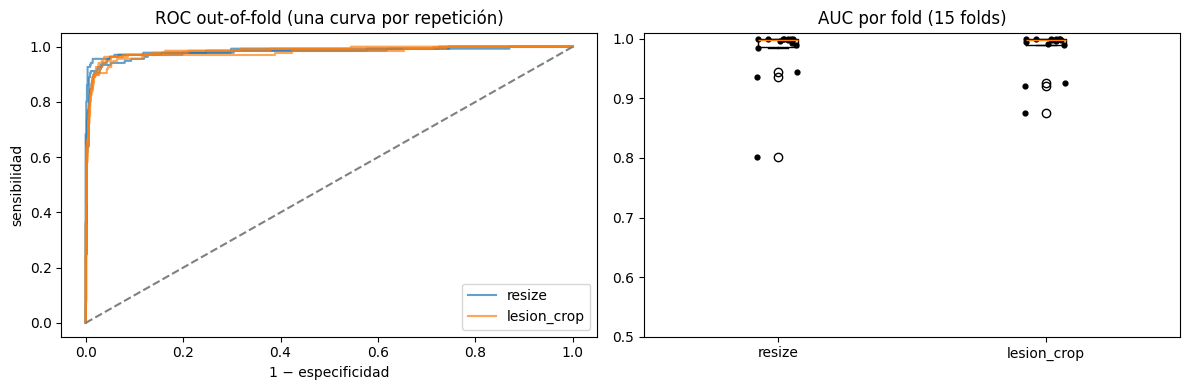

In [10]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for p in PREPROCS:
    y = df.target.values
    for r in range(N_REPEATS):
        fpr, tpr, _ = roc_curve(y, df[f"p_{p}_r{r}"])
        ax[0].plot(fpr, tpr, c="C0" if p == "resize" else "C1", alpha=0.7, label=p if r == 0 else None)
ax[0].plot([0, 1], [0, 1], ls="--", c="grey")
ax[0].set(title="ROC out-of-fold (una curva por repetición)", xlabel="1 − especificidad", ylabel="sensibilidad")
ax[0].legend()
data = [fold_aucs[fold_aucs.preproc == p].auc for p in PREPROCS]
ax[1].boxplot(data); ax[1].set_xticks(range(1, len(PREPROCS) + 1), PREPROCS)
for i, d in enumerate(data, 1):
    ax[1].scatter(np.full(len(d), i) + np.random.default_rng(0).uniform(-0.08, 0.08, len(d)), d, s=12, c="k")
ax[1].set(title="AUC por fold (15 folds)", ylim=(0.5, 1.01))
plt.tight_layout(); plt.show()

### Desgloses: cámara, subgrupo, split del paper

Sensibilidad y especificidad juntando las 3 repeticiones. Si una cámara tiene sensibilidad
mucho menor, el modelo podría estar usando el "aspecto de la cámara" como atajo.

In [11]:
def breakdown(by: str) -> pd.DataFrame:
    out = []
    for p in PREPROCS:
        stacked = pd.concat([df.assign(prob=df[f"p_{p}_r{r}"], pred=df[f"pred_{p}_r{r}"])
                             for r in range(N_REPEATS)])
        for g, s in stacked.groupby(by):
            out.append({"preproc": p, by: g, "imgs": len(s) // N_REPEATS,
                        "melanomas": int(s.target.sum()) // N_REPEATS, **rates(s.target.values, s.prob.values, s.pred.values)})
    return pd.DataFrame(out).set_index(["preproc", by]).round(3)

for by in ("camera", "subgroup", "split"):
    print(f"Por {by}:"); display(breakdown(by))

Por camera:


imgs  melanomas    auc  sensibilidad  especificidad  \
preproc     camera                                                           
resize      1920×1080    75          0    NaN           NaN          0.960   
            2048×1536    11          8  0.977         0.833          1.000   
            3264×2448   139          9  0.952         0.889          0.941   
            4032×3024   110          9  0.997         1.000          0.970   
            768×576     440         40  0.961         0.800          0.955   
            irregular   121         70  0.997         0.981          0.908   
lesion_crop 1920×1080    75          0    NaN           NaN          0.973   
            2048×1536    11          8  0.991         0.958          0.889   
            3264×2448   139          9  0.952         0.889          0.933   
            4032×3024   110          9  0.996         1.000          0.950   
            768×576     440         40  0.960         0.808          0.946   
            irregular   121         70  0.995         0.967          0.895   

                      melanomas_detectados falsas_alarmas  
preproc     camera                                         
resize      1920×1080                  0/0          9/225  
            2048×1536                20/24            0/9  
            3264×2448                24/27         23/390  
            4032×3024                27/27          9/303  
            768×576                 96/120        54/1200  
            irregular              206/210         14/153  
lesion_crop 1920×1080                  0/0          6/225  
            2048×1536                23/24            1/9  
            3264×2448                24/27         26/390  
            4032×3024                27/27         15/303  
            768×576                 97/120        65/1200  
            irregular              203/210         16/153

Por subgroup:


imgs  melanomas    auc  sensibilidad  especificidad  \
preproc     subgroup                                                         
resize      estándar    775         66  0.967         0.843          0.955   
            recortada   121         70  0.997         0.981          0.908   
lesion_crop estándar    775         66  0.969         0.864          0.947   
            recortada   121         70  0.995         0.967          0.895   

                      melanomas_detectados falsas_alarmas  
preproc     subgroup                                       
resize      estándar               167/198        95/2127  
            recortada              206/210         14/153  
lesion_crop estándar               171/198       113/2127  
            recortada              203/210         16/153

Por split:


imgs  melanomas    auc  sensibilidad  especificidad  \
preproc     split                                                        
resize      test    181         28  0.937         0.786          0.952   
            train   715        108  0.994         0.948          0.952   
lesion_crop test    181         28  0.939         0.810          0.948   
            train   715        108  0.993         0.944          0.942   

                  melanomas_detectados falsas_alarmas  
preproc     split                                      
resize      test                 66/84         22/459  
            train              307/324        87/1821  
lesion_crop test                 68/84         24/459  
            train              306/324       105/1821

### Pacientes con melanoma

Una fila por cada uno de los 24 pacientes: qué fracción de sus imágenes se detecta (media
de las 3 repeticiones). Los pacientes con fracción baja son los casos difíciles: merece la pena
mirar sus imágenes.

In [12]:
mel_df = df[df.target == 1]
tab = mel_df.groupby("patient_id").agg(
    imgs=("isic_id", "size"), split_paper=("split", "first"),
    tipos=("label", lambda s: ",".join(sorted(set(s)))),
    camaras=("camera", lambda s: ",".join(sorted(set(s)))))
for p in PREPROCS:
    tab[f"p_media_{p}"] = mel_df.groupby("patient_id")[[f"p_{p}_r{r}" for r in range(N_REPEATS)]].mean().mean(axis=1)
    tab[f"detectadas_{p}"] = mel_df.groupby("patient_id")[[f"pred_{p}_r{r}" for r in range(N_REPEATS)]].mean().mean(axis=1)
tab.sort_values(f"detectadas_{PREPROCS[0]}").round(2)

,imgs,split_paper,tipos,camaras,p_media_resize,detectadas_resize,p_media_lesion_crop,detectadas_lesion_crop
patient_id,,,,,,,,
IP_1087262,3,test,alm,"3264×2448,768×576",0.01,0.00,0.01,0.00
IP_3435513,5,test,alm,"3264×2448,768×576",0.45,0.40,0.48,0.53
IP_9536752,5,train,alm,768×576,0.61,0.53,0.51,0.40
IP_8539848,3,train,alm,768×576,0.82,0.78,0.93,0.89
IP_7586979,15,train,anm,"2048×1536,irregular",0.79,0.91,0.83,0.98
IP_7133018,5,train,alm,irregular,0.93,0.93,0.91,0.93
IP_3704432,22,train,"alm,anm",irregular,0.94,0.95,0.91,0.91
IP_1007527,5,test,anm,768×576,0.99,1.00,1.00,1.00
IP_1054647,1,test,alm,3264×2448,0.95,1.00,0.72,1.00


## 4 · Guardar

In [13]:
import json
from datetime import datetime

def clean(o):
    if isinstance(o, dict):
        return {str(k): clean(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [clean(v) for v in o]
    if isinstance(o, (np.floating, float)):
        return None if np.isnan(o) else float(o)
    if isinstance(o, np.integer):
        return int(o)
    return o

report = {
    "run": RUN_NAME, "fecha": f"{datetime.now():%Y-%m-%d %H:%M}",
    "config": {"preprocs": PREPROCS, "n_folds": N_FOLDS, "n_repeats": N_REPEATS, "seed": SEED,
               "img_size": IMG_SIZE, "cache_size": CACHE_SIZE, "crop_margin": CROP_MARGIN,
               "epochs": EPOCHS, "batch_size": BATCH_SIZE, "lr": LR, "weight_decay": WEIGHT_DECAY,
               "target_sensitivity": TARGET_SENSITIVITY},
    "por_repeticion": per_rep.to_dict("records"),
    "auc_por_fold": fold_aucs.to_dict("records"),
    "resumen": {f"{a}_{b}": summary[(a, b)].to_dict() for a, b in summary.columns},
    "por_camara": breakdown("camera").reset_index().to_dict("records"),
    "por_split_paper": breakdown("split").reset_index().to_dict("records"),
    "pacientes_melanoma": tab.reset_index().to_dict("records"),
}
(OUT_DIR / f"{RUN_NAME}_report.json").write_text(json.dumps(clean(report), indent=2, ensure_ascii=False))
keep = ["isic_id", "patient_id", "label", "split", "camera", "subgroup", "target"]
df[keep + [c for c in df.columns if c.startswith(("fold_r", "p_", "pred_"))]].to_csv(oof_path, index=False)
print("Guardado:", OUT_DIR / f"{RUN_NAME}_report.json", "y", oof_path)

Guardado: /kaggle/working/outputs/v3_repeated_cv_report.json y /kaggle/working/outputs/v3_repeated_cv_oof.csv
